# 02 — Up/Down State Analysis

Run the full analysis across conditions, compute duration metrics, delta durations, and statistical comparisons.

In [ ]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

from src.config import load_config
from src.data_io import list_h5_files, save_results
from src.core.experiment import Experiment

cfg = load_config()
print('Conditions:', cfg['conditions'])


Conditions: ['baseline', 'stimulation', 'post_stimulation']


## Run analysis on all recordings

This block loops over all `.h5` files, infers the condition from the filename, and runs the pipeline.

In [2]:
from scripts.batch_process_slices import _parse_condition_from_filename

h5_files   = list_h5_files(cfg['paths']['condition_dir'])
conditions = cfg['conditions']
experiments = {}   # {(slice_id, condition): Experiment}
summary_rows = []

for h5_path in h5_files:
    condition = _parse_condition_from_filename(h5_path, conditions)
    if condition is None:
        print(f'SKIP (no condition found): {os.path.basename(h5_path)}')
        continue
    exp = Experiment(h5_path, condition=condition, cfg=cfg)
    exp.run()
    experiments[(exp.slice_id, condition)] = exp
    summary_rows.append(exp.summary_row)

if summary_rows:
    summary_df = pd.concat(summary_rows, ignore_index=True)
    print(summary_df[['slice_id','condition','n_up','mean_up_s','mean_down_s','so_frequency']])
else:
    print('No recordings found. Add .h5 files to data/processed/')
    summary_df = pd.DataFrame()


[20260414_SLICE3_CONTROL_Nathalia_vitaly_trial_01_baseline | baseline] Running full analysis...
  Loaded 140625 samples × 32 channels @ 3125.0000000000005 Hz
  Features extracted: shape (44800, 3), downsampled to 1000.0 Hz
  State detection: 6 Up states, 7 Down states (threshold = 4.122)
  Firing rates: mean Up FR = 3.320, mean Down FR = 2.701
[20260414_SLICE3_CONTROL_Nathalia_vitaly_trial_01_baseline | baseline] Done. Detected 6 Up states, 7 Down states.
[20260414_SLICE3_CONTROL_Nathalia_vitaly_trial_01_post_stimulation | post_stimulation] Running full analysis...
  Loaded 140625 samples × 32 channels @ 3125.0000000000005 Hz
  Features extracted: shape (44800, 3), downsampled to 1000.0 Hz
  State detection: 3 Up states, 4 Down states (threshold = 5.241)
  Firing rates: mean Up FR = 3.682, mean Down FR = 2.737
[20260414_SLICE3_CONTROL_Nathalia_vitaly_trial_01_post_stimulation | post_stimulation] Done. Detected 3 Up states, 4 Down states.
[20260414_SLICE3_CONTROL_Nathalia_vitaly_trial_0

## Duration distributions per condition

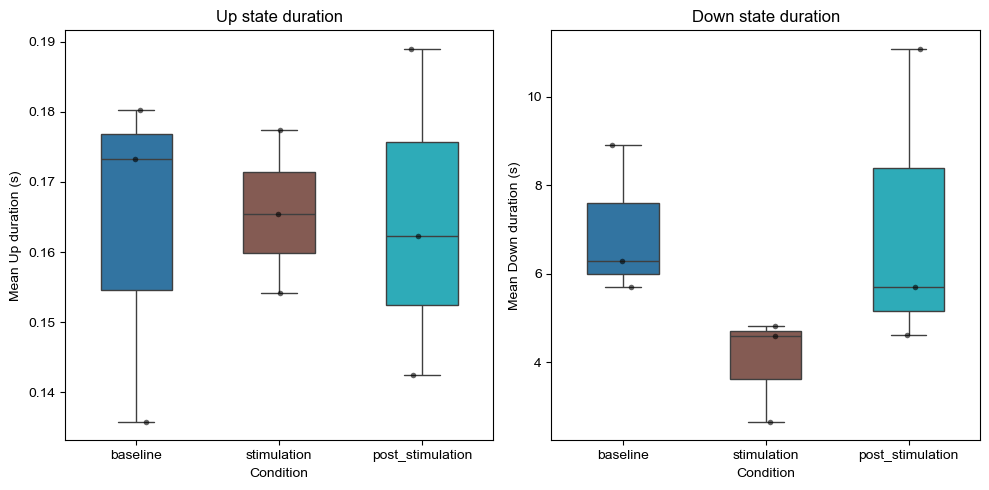

In [3]:
if not summary_df.empty:
    from src.visualization import plot_duration_boxplot
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    plot_duration_boxplot(summary_df, 'up',   cfg, ax=axes[0])
    plot_duration_boxplot(summary_df, 'down', cfg, ax=axes[1])
    plt.tight_layout()
    plt.show()


## SO frequency per condition

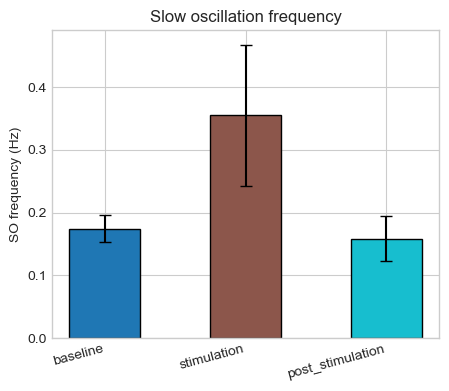

In [4]:
if not summary_df.empty:
    from src.visualization import plot_so_frequency
    fig, ax = plot_so_frequency(summary_df, cfg)
    plt.show()


## Delta duration (stimulation − baseline)

In [5]:
from src.core.metrics import compute_delta_duration

baseline_cond = cfg.get('baseline_condition', cfg['conditions'][0])
comparison_cond = 'stimulation'   # ← change to your comparison condition

delta_up, delta_down = [], []

# Group by condition instead of slice_id
for condition in [baseline_cond, comparison_cond]:
    cond_data = summary_df[summary_df['condition'] == condition]
    if cond_data.empty:
        continue
    
    if condition == baseline_cond:
        baseline_up = cond_data['mean_up_s'].values
        baseline_down = cond_data['mean_down_s'].values
    else:
        comparison_up = cond_data['mean_up_s'].values
        comparison_down = cond_data['mean_down_s'].values

# Calculate deltas across all slices
if 'baseline_up' in locals() and 'comparison_up' in locals():
    delta_up = [comp - bl for comp, bl in zip(comparison_up, baseline_up)]
    delta_down = [comp - bl for comp, bl in zip(comparison_down, baseline_down)]

    print(f'Δ Up duration   : {np.mean(delta_up):.3f} ± {np.std(delta_up, ddof=1)/np.sqrt(len(delta_up)):.3f} s  (n={len(delta_up)})')
    print(f'Δ Down duration : {np.mean(delta_down):.3f} ± {np.std(delta_down, ddof=1)/np.sqrt(len(delta_down)):.3f} s  (n={len(delta_down)})')
else:
    print("Error: Could not find both baseline and comparison conditions in data")

Δ Up duration   : 0.003 ± 0.008 s  (n=3)
Δ Down duration : -2.946 ± 0.926 s  (n=3)
